In [95]:
from pathlib import Path
import pandas as pd
from pydeseq2.dds import DeseqDataSet
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np

In [63]:
# The data available is here :
DATA_DIR = Path.cwd().parent / "data"

## Glioma interpretation table

In [64]:
glioma_class = pd.read_csv(DATA_DIR / "glioma-classification-and-mutations.csv")

In [65]:
glioma_class.head()

,patient,tcga_project,idh_status,codeletion_1p19q_status,historical_histology,historical_grade,historical_label_status,who_cns5_entity,who_cns5_grade,who_cns5_assignment_status,...,mutation_profile_present,atrx_used_in_who_assignment,tp53_status,tp53_driver_evidence,tp53_driver_variant_count,tp53_other_variant_count,atrx_status,atrx_driver_evidence,atrx_driver_variant_count,atrx_other_variant_count
0,TCGA-06-0125,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0
1,TCGA-06-0190,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,driver_supported,two_concordant_tp53_function_assays,1,0,no_reported_variant,NaN,0,0
2,TCGA-06-0210,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,driver_supported,two_concordant_tp53_function_assays,1,0,no_reported_variant,NaN,0,0
3,TCGA-06-0211,GBM,wildtype,not_codeleted,glioblastoma,G4,historical_comparator,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0
4,TCGA-06-1804,GBM,wildtype,not_codeleted,glioblastoma,G4,source_conflict,"Glioblastoma, IDH-wildtype",4,provisional_research_reconstruction,...,True,False,no_reported_variant,NaN,0,0,no_reported_variant,NaN,0,0


## TCGA-LGG + TCGA-GBM

In [66]:
tcga_gbm = pd.read_csv(DATA_DIR / "tcga_gbm_wsi_ids.txt", header=None, names=["tcga_gbm"], dtype="string")

tcga_paad = pd.read_csv(DATA_DIR / "tcga_paad_wsi_ids.txt", header=None, names=["tcga_paad"], dtype="string")

In [67]:
tcga_gbm.head()

,tcga_gbm
0,TCGA-02-0025-01Z-00-DX1.bea1009d-61ab-48dc-a6a...
1,TCGA-02-0026-01Z-00-DX1.d8f3085f-e418-47da-86b...
2,TCGA-02-0010-01Z-00-DX1.b53f8c4e-6e10-4684-b7f...
3,TCGA-RR-A6KB-01Z-00-DX1.90E22C0F-CA68-4EEB-BB1...
4,TCGA-RR-A6KC-01Z-00-DX1.1D8F656F-9A5D-4143-847...


## Clinical records and sample QC

In [68]:
sample_QC = pd.read_csv(DATA_DIR / "merged_sample_quality_annotations.tsv", sep='\t')


In [69]:
sample_QC.head()

,patient_barcode,aliquot_barcode,cancer type,platform,patient_annotation,sample_annotation,aliquot_annotation,aliquot_annotation_updated,AWG_excluded_because_of_pathology,AWG_pathology_exclusion_reason,Reviewed_by_EPC,Do_not_use
0,TCGA-01-0628,TCGA-01-0628-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
1,TCGA-01-0628,TCGA-01-0628-11A-01D-0383-05,OV,HumanMethylation27,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
2,TCGA-01-0630,TCGA-01-0630-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
3,TCGA-01-0630,TCGA-01-0630-11A-01D-0383-05,OV,HumanMethylation27,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False
4,TCGA-01-0631,TCGA-01-0631-11A-01D-0356-01,OV,Genome_Wide_SNP_6,Organ-Specific Control,NaN,NaN,NaN,0.0,NaN,0.0,False


In [70]:
clinical_records = pd.read_csv(DATA_DIR / "clinical_PANCAN_patient_with_followup.tsv", sep='\t', encoding='Latin1')

/tmp/ipykernel_1657/3030050661.py:1: DtypeWarning: Columns (8: days_to_initial_pathologic_diagnosis, 9: age_at_initial_pathologic_diagnosis, 27: year_of_initial_pathologic_diagnosis, 42: postoperative_rx_tx, 44: lymph_node_examined_count, 45: primary_lymph_node_presentation_assessment, 46: initial_pathologic_diagnosis_method, 47: number_of_lymphnodes_positive_by_he, 48: eastern_cancer_oncology_group, 49: anatomic_neoplasm_subdivision, 50: residual_tumor, 51: histological_type_other, 52: init_pathology_dx_method_other, 53: karnofsky_performance_score, 55: height, 56: weight, 57: history_of_radiation_metastatic_site, 58: days_to_patient_progression_free, 59: days_to_first_response, 60: days_to_first_partial_response, 61: days_to_first_complete_response, 62: days_to_tumor_progression, 63: er_estimated_duration_response, 64: er_disease_extent_prior_er_treatment, 65: er_solid_tumor_response_documented_type, 66: er_solid_tumor_response_documented_type_other, 67: er_response_type, 68: history

In [71]:
clinical_records.head()

,bcr_patient_uuid,bcr_patient_barcode,acronym,gender,vital_status,days_to_birth,days_to_death,days_to_last_followup,days_to_initial_pathologic_diagnosis,age_at_initial_pathologic_diagnosis,...,total_bilirubin_upper_limit,platelet_result_count,fibrosis_ishak_score,fetoprotein_outcome_value,fetoprotein_outcome_upper_limit,fetoprotein_outcome_lower_limit,inter_norm_ratio_lower_limit,family_cancer_type_txt,bilirubin_upper_limit,days_to_last_known_alive
0,B3164F7B-C826-4E08-9EE6-8FF96D29B913,TCGA-OR-A5J1,ACC,MALE,Dead,-21496,1355.0,[Not Available],0,58,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8E7C2E31-D085-4B75-A970-162526DD07A0,TCGA-OR-A5J2,ACC,FEMALE,Dead,-16090,1677,[Not Available],0,44,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,DFD687BC-6E69-42F7-AF94-D17FC150D1A1,TCGA-OR-A5J3,ACC,FEMALE,Alive,-8624,[Not Applicable],2091.0,0,23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,5F3E2974-F1DF-47A2-8A8A-29BB525EEEF6,TCGA-OR-A5J4,ACC,FEMALE,Dead,-8451,423,[Not Available],0,23,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,802DBD0D-EF07-4C91-AB8D-1DD39532E947,TCGA-OR-A5J5,ACC,MALE,Dead,-11171,365,[Not Available],0,30,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Make a patient inventory for glioma. Start with the clinical and sample-quality tables. Match primary tumour samples from LGG and GBM to the RNA, methylation and slide files by TCGA patient barcode. Count unique patients with each assay, with both molecular assays and with all three inputs. Document exclusions and how you handle multiple samples or slides from one patient.

In [109]:
metadata_LGG = sample_QC[sample_QC["cancer type"] == 'LGG']
metadata_GBM = sample_QC[sample_QC["cancer type"] == 'GBM']

metadata_LGG_GBM = pd.concat([metadata_LGG, metadata_GBM], axis=0, ignore_index=False, join="outer")
metadata_LGG_GBM = metadata_LGG_GBM.set_index("aliquot_barcode")
metadata_LGG_GBM = metadata_LGG_GBM[~metadata_LGG_GBM.index.duplicated(keep="first")] 


## RNAseq Preprocessing

In [73]:
counts_path = DATA_DIR / "EBPlusPlusAdjustPANCAN_IlluminaHiSeq_RNASeqV2.geneExp.tsv"
expr_count = pd.read_csv(counts_path,index_col = 0, delimiter = "\t", na_values = "NaN")



In [101]:


expr_count = expr_count.fillna(0) # Remplace missing values µby 0
expr_count = expr_count.astype("int32")
counts_df = expr_count.T # Transpose to get a matrix samples x genes
# counts_df.set_index('sample', inplace=True) # Set the sample column as index


NaN : 0 | min/max : 0 9924360
count    2.272576e+08
mean     9.902324e+02
std      7.726882e+03
min      0.000000e+00
50%      1.850000e+02
90%      2.051000e+03
99%      1.127200e+04
max      9.924360e+06
dtype: float64


Text(0.5, 1.0, 'log2(x+1)')

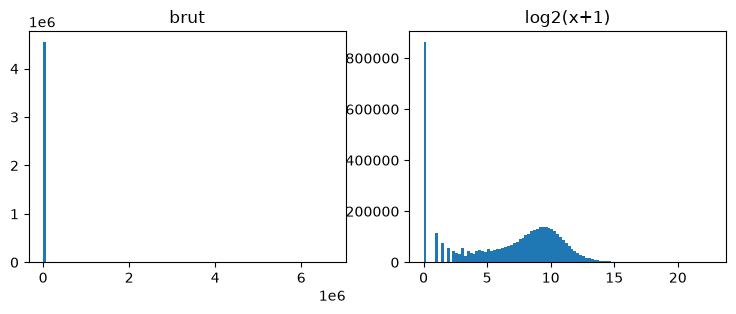

In [ ]:
# Visualize the distribution of expression values, and log-transform them to see if they are more normally distributed
vals = expr_count.to_numpy().ravel()
print("NaN :", np.isnan(vals).sum(), "| min/max :", np.nanmin(vals), np.nanmax(vals))
print(pd.Series(vals).describe(percentiles=[.5, .9, .99]))
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].hist(vals[~np.isnan(vals)][::50], bins=100); ax[0].set_title("Raw data")
ax[1].hist(np.log2(vals[~np.isnan(vals)][::50] + 1), bins=100); ax[1].set_title("log2(x+1)")

In [111]:
#Find common samples
common_samples = (counts_df.index).intersection(metadata_LGG_GBM.index)

#Filter and order the two tables
counts_df = counts_df.loc[common_samples]
metadata_LGG_GBM = metadata_LGG_GBM.loc[common_samples]
# counts_GBM = counts_df.loc[GBM_samples]
# counts_LGG = counts_df.loc[LGG_samples]


In [ ]:
# log-transform  
# !! Run only once !! 
counts_df_log = np.log2(counts_df.loc[metadata_LGG_GBM.index] + 1) 

Index(['TCGA-02-0047-01A-01R-1849-01', 'TCGA-02-0055-01A-01R-1849-01',
       'TCGA-02-2483-01A-01R-1849-01', 'TCGA-02-2485-01A-01R-1849-01',
       'TCGA-02-2486-01A-01R-1849-01', 'TCGA-06-0125-01A-01R-1849-01',
       'TCGA-06-0125-02A-11R-2005-01', 'TCGA-06-0129-01A-01R-1849-01',
       'TCGA-06-0130-01A-01R-1849-01', 'TCGA-06-0132-01A-02R-1849-01',
       ...
       'TCGA-VW-A8FI-01A-11R-A36H-07', 'TCGA-W9-A837-01A-11R-A36H-07',
       'TCGA-WH-A86K-01A-11R-A36H-07', 'TCGA-WY-A858-01A-11R-A36H-07',
       'TCGA-WY-A859-01A-12R-A36H-07', 'TCGA-WY-A85A-01A-21R-A36H-07',
       'TCGA-WY-A85B-01A-11R-A36H-07', 'TCGA-WY-A85C-01A-11R-A36H-07',
       'TCGA-WY-A85D-01A-11R-A36H-07', 'TCGA-WY-A85E-01A-11R-A36H-07'],
      dtype='str', name='aliquot_barcode', length=708)


In [113]:
deseqexpr = DeseqDataSet(counts=counts_df,
    metadata=metadata_LGG_GBM,
    design="~ 1"
)
deseqexpr

AnnData object with n_obs × n_vars = 708 × 20531
    obs: 'patient_barcode', 'cancer type', 'platform', 'patient_annotation', 'sample_annotation', 'aliquot_annotation', 'aliquot_annotation_updated', 'AWG_excluded_because_of_pathology', 'AWG_pathology_exclusion_reason', 'Reviewed_by_EPC', 'Do_not_use'
    obsm: 'design_matrix'
    layers: None (.X)

<bound method NDFrame.head of gene_id                       ?|100130426  ?|100133144  ?|100134869   ?|10357  \
TCGA-02-0047-01A-01R-1849-01          0.0     2.000000     2.807355  5.781360   
TCGA-02-0055-01A-01R-1849-01          0.0     0.000000     4.000000  5.000000   
TCGA-02-2483-01A-01R-1849-01          0.0     1.584963     3.807355  5.930737   
TCGA-02-2485-01A-01R-1849-01          0.0     4.000000     3.906891  6.523562   
TCGA-02-2486-01A-01R-1849-01          0.0     2.584963     2.321928  5.977280   
...                                   ...          ...          ...       ...   
TCGA-WY-A85A-01A-21R-A36H-07          0.0     2.584963     4.087463  6.965784   
TCGA-WY-A85B-01A-11R-A36H-07          0.0     3.169925     4.321928  7.066089   
TCGA-WY-A85C-01A-11R-A36H-07          0.0     3.584963     4.247928  6.918863   
TCGA-WY-A85D-01A-11R-A36H-07          0.0     2.584963     3.169925  6.754888   
TCGA-WY-A85E-01A-11R-A36H-07          0.0     3.321928     3.000000  7.169925  

In [ ]:
cohort_map = metadata_LGG_GBM.loc[common_samples, "cancer type"]
lgg_cols = cohort_map.index[cohort_map == "LGG"].tolist()
gbm_cols = cohort_map.index[cohort_map == "GBM"].tolist()
assert not set(lgg_cols) & set(gbm_cols)

# variance of each gene in each cancer group
var_lgg = counts_df_log.loc[lgg_cols].var(axis=0, ddof=1)
var_gbm = counts_df_log.loc[gbm_cols].var(axis=0, ddof=1)

valid_genes = var_lgg.index[(var_lgg > 0) & (var_gbm > 0)]
var_lgg = var_lgg.loc[valid_genes]
var_gbm = var_gbm.loc[valid_genes]

within_cohort_var = 0.5 * (var_lgg + var_gbm)

top_n = min(5000, len(within_cohort_var))
top_genes = within_cohort_var.sort_values(ascending=False).head(top_n).index

# matrix patients x genes
counts_df_filtered = counts_df_log.loc[lgg_cols + gbm_cols, top_genes]
print(counts_df_filtered.shape, len(lgg_cols), len(gbm_cols))

(708, 5000) 534 174


In [122]:
#Matrix for PCA : samples in rows, genes in columns:
pca_matrix = counts_df_filtered.copy()

#Run PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(pca_matrix)

pca_df = pd.DataFrame(
    coords,
    index=pca_matrix.index,  
    columns=["PC1", "PC2"],
)
var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

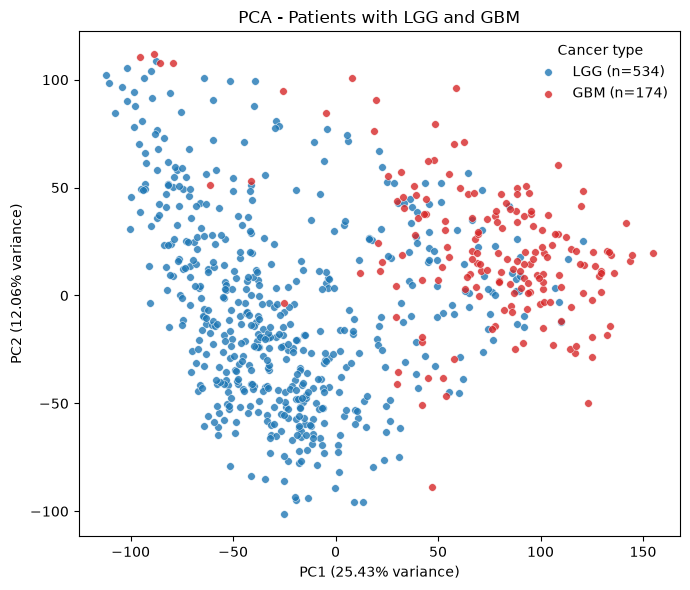

In [125]:
from matplotlib.lines import Line2D

#Add colours for each cohort
colours = {"LGG": "#1f77b4", "GBM": "#d62728"}  

cohort = pd.Series(
    ["LGG"] * len(lgg_cols) + ["GBM"] * len(gbm_cols),
    index=lgg_cols + gbm_cols,
)
pca_df["cancer type"] = cohort.loc[pca_df.index].values

fig, ax = plt.subplots(figsize=(7, 6))
for name, color in colours.items():
    sub = pca_df[pca_df["cancer type"] == name]
    ax.scatter(sub["PC1"], sub["PC2"], c=color, alpha=0.8,
               s=30, edgecolor="white", linewidth=0.4,
               label=f"{name} (n={len(sub)})")

ax.set_xlabel(f"PC1 ({var_pc1:.2f}% variance)")
ax.set_ylabel(f"PC2 ({var_pc2:.2f}% variance)")
ax.set_title("PCA - Patients with LGG and GBM")
ax.legend(title="Cancer type", frameon=False)
plt.tight_layout()
plt.savefig("pca_coloured.png", dpi=300)
plt.show()
plt.close(fig)

In [ ]:
# Save the figure and the PCA coordinates to CSV
# pca_df.to_csv("pca_coordinates_RNAseq.csv")